# STL Decomposition (Trend / Seasonal / Residual)

**Family:** Change over time &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Change over time:* Emphasise changing trends, from intraday moves to series spanning decades.

## Design purpose

Splits a time series into three additive parts with STL (Seasonal-Trend decomposition using LOESS): a smooth trend, a repeating seasonal pattern that can change slowly, and a residual. Stacked panels on a shared time axis separate the questions "is it growing?", "what is the seasonal pattern?" and "was this month unusual?", which a single line mixes together.

## When to use

- Separate long-term growth from seasonality before reporting a trend
- Find unusual periods (large residuals) such as outages, strikes or promotions
- Check whether the seasonal pattern is changing over time

## Avoid when

- The series has no clear seasonality or is very short (fewer than ~3 full cycles)
- Effects are multiplicative and growing fast (log-transform first)

## Alternatives

- Seasonal cycle plot
- Line chart with a moving average
- ACF/PACF plots

## Design tips

- Give each panel its own y-scale but keep the x-axis shared
- Draw residuals as bars or points around zero, not as a connected line
- Use the robust option so outliers land in the residual, not the trend

## Example

Monthly electricity demand, 2010–2024 (simulated): a rising then flattening trend, summer and winter peaks that grow over time, and a few anomalies (a heat wave and a lockdown dip).

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

from statsmodels.tsa.seasonal import STL

### Data

In [2]:
rng = np.random.default_rng(4)
idx = pd.date_range("2010-01-01", "2024-12-01", freq="MS")
t = np.arange(len(idx))
trend = 300 + 1.1 * np.minimum(t, 110) + 0.15 * np.maximum(t - 110, 0)
amp_summer = 25 + 0.12 * t
season = amp_summer * np.exp(-((idx.month - 7.5) / 1.3) ** 2) + 20 * np.exp(-((idx.month % 12 - 0.5) / 1.4) ** 2)
noise = rng.normal(0, 4, len(idx))
shock = np.zeros(len(idx))
shock[(idx >= "2020-04-01") & (idx <= "2020-06-01")] = -28      # lockdown dip
shock[idx == "2022-07-01"] = 30                                   # heat wave
demand = pd.Series(trend + season + noise + shock, index=idx, name="demand (GWh)")
demand.tail(6).round(1)

2024-07-01    472.9
2024-08-01    472.1
2024-09-01    448.8
2024-10-01    435.5
2024-11-01    426.3
2024-12-01    452.0
Freq: MS, Name: demand (GWh), dtype: float64

### Plot

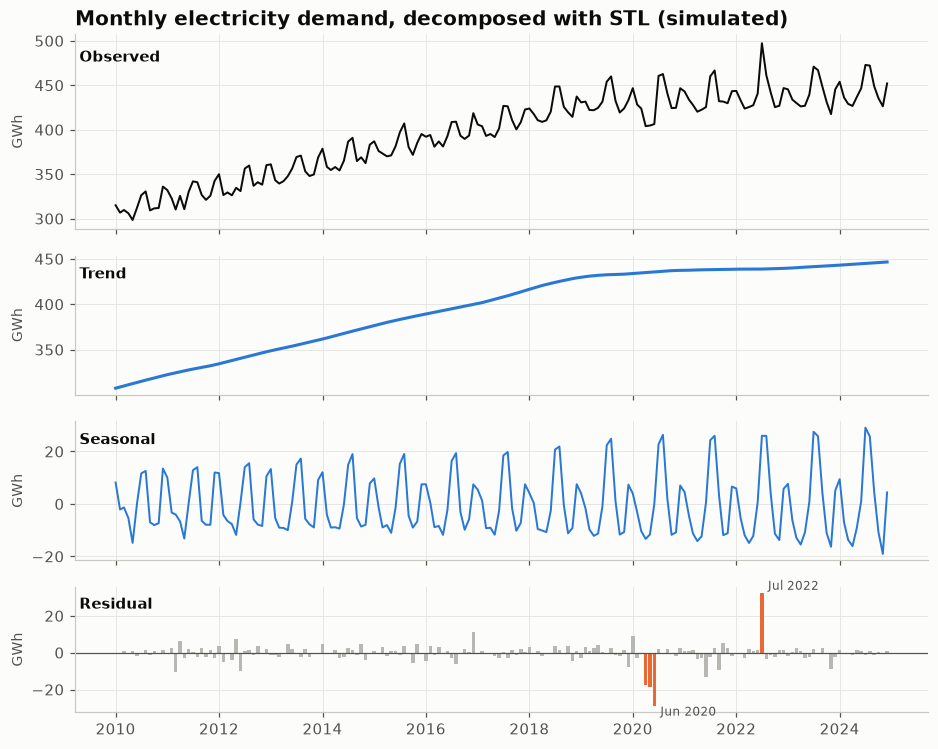

In [3]:
res = STL(demand, period=12, robust=True).fit()
parts = [("Observed", demand), ("Trend", res.trend), ("Seasonal", res.seasonal), ("Residual", res.resid)]
fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1.4, 1, 1, 0.9], "hspace": 0.18})
for ax, (name, s) in zip(axes, parts):
    if name == "Residual":
        big = s.abs() > 3 * s.std()
        ax.bar(s.index, s, width=25, color=np.where(big, PALETTE[1], "#b8b7b1"))
        ax.axhline(0, color="#52514e", linewidth=0.8)
        for d, v in (s[big].nlargest(1).items() if (s[big] > 0).any() else []):
            ax.annotate(f"{d:%b %Y}", (d, v), xytext=(4, 0), textcoords="offset points",
                        fontsize=8, color="#52514e", va="bottom")
        for d, v in (s[big].nsmallest(1).items() if (s[big] < 0).any() else []):
            ax.annotate(f"{d:%b %Y}", (d, v), xytext=(4, 0), textcoords="offset points",
                        fontsize=8, color="#52514e", va="top")
    else:
        ax.plot(s.index, s, color="#0b0b0b" if name == "Observed" else PALETTE[0],
                linewidth=1.3 if name != "Trend" else 2)
    ax.text(0.005, 0.92, name, transform=ax.transAxes, fontsize=10, fontweight="bold", va="top")
    ax.set_ylabel("GWh", fontsize=9)
axes[0].set_title("Monthly electricity demand, decomposed with STL (simulated)")
fig.align_ylabels(axes)
plt.show()

## How to read it

Observed demand (top) is the sum of the three panels below. The trend rises until about 2019 and then flattens. The seasonal panel shows a double peak each year, summer and winter, whose summer peak grows larger. The residual panel isolates the 2020 lockdown dip and the 2022 heat wave as large bars.

---
Standalone script: [`stl_decomposition.py`](stl_decomposition.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)